# HOMEWORK 9

In this homework, you are going to use the dlib face detector and apply it to an image of your liking. You can follow the procedure shown in lesson 9. Please always comment your code so I can see what you're doing :-)

For this homework we are not going to provide you with any code, you'll have to build the face detector on your own.

### Step 0

Run the necessary imports.

In [101]:
import cv2
import math
import numpy as np
import dlib
from matplotlib import pyplot as plt

plt.rcParams['figure.figsize'] = [15, 10]
# declare paths
eu_summit_img_path = "../data/eu_summit.jpg"
selfie_img_path = "../data/selfie.jpg"
# define colors for us to pick
COLOR_RED   = (0, 0, 255)
COLOR_GREEN = (0, 255, 0)
COLOR_BLUE  = (255, 0, 0)
COLOR_WHITE = (255, 255, 255)
COLOR_BLACK = (0, 0, 0)

# my function to display images in convinient for me way
def display_image(img, title="", show_axis = True):
    if isinstance(img, list):
        plt.figure()
        for idx, image in enumerate(img):
            plt.subplot(1,len(img),idx+1)
            # use proper color map for the gray image
            # we know that gray image has 1 channel
            if len(image.shape) == 2 or (len(image.shape) == 3 and image.shape[2] == 1):
                print("here") 
                plt.imshow(image, cmap='gray')
            else:
                 plt.imshow(image)
            plt.title(title[idx])
    else:
        plt.figure()
        if len(image.shape) == 2 or (len(image.shape) == 3 and image.shape[2] == 1):
            plt.imshow(image, cmap='gray')
        else:
            plt.imshow(image)
        plt.title(title)
    
    if show_axis == False:
        plt.axis('off')



### Step 1

Load an image (any image that contains faces).

In [102]:
# lets load with dlib image and convert to gray with opencv
img = dlib.load_rgb_image(eu_summit_img_path)
img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

### Step 2

Load the dlib face predictor.

In [103]:
dlbib_face_detector = dlib.get_frontal_face_detector()

### Step 3

Run the predictor on your image.

In [104]:
# lets make a function to make detection and an upsample parameter to test the different results depending on upsample
def dlib_face_detector(img, face_detector, upsample):
    rects = face_detector(img_gray, upsample)
    print(f"Number of faces detected: {len(rects)}")
    return rects

### Step 4

Draw bounding boxes around the detected faces and plot the image. Use different colour for each face.

Number of faces detected: 3
Number of faces detected: 8
Number of faces detected: 8
Number of faces detected: 8
Number of faces detected: 8


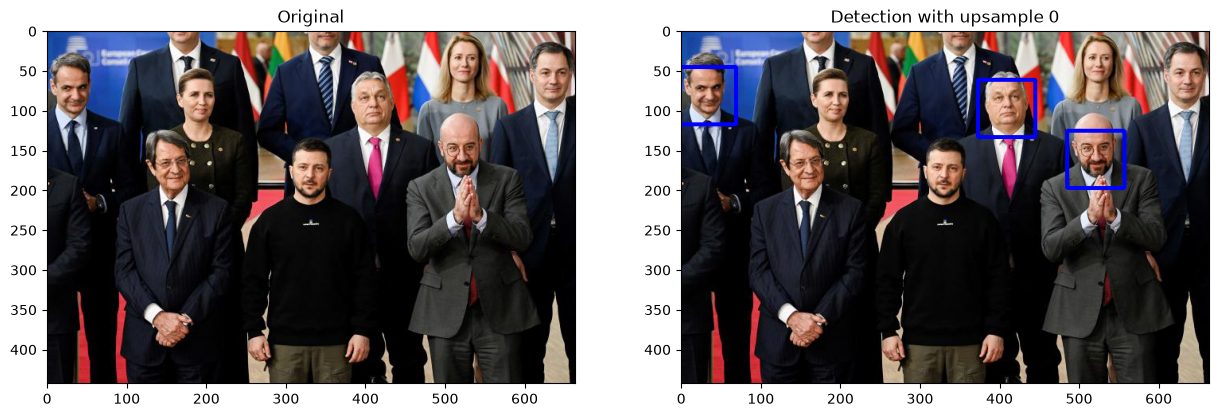

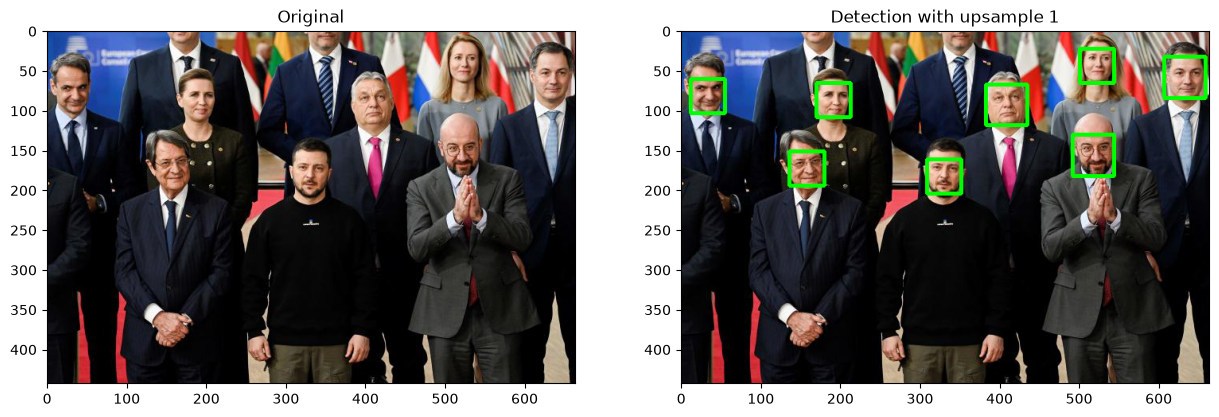

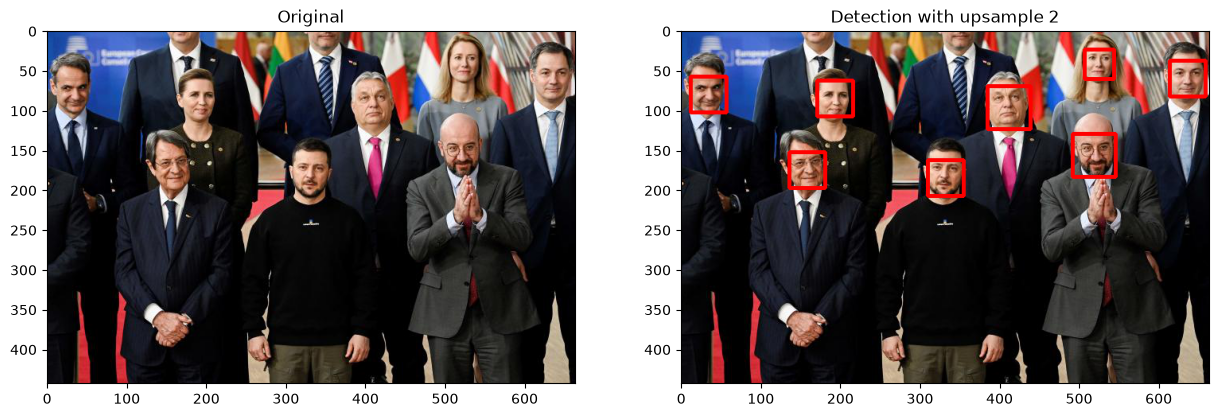

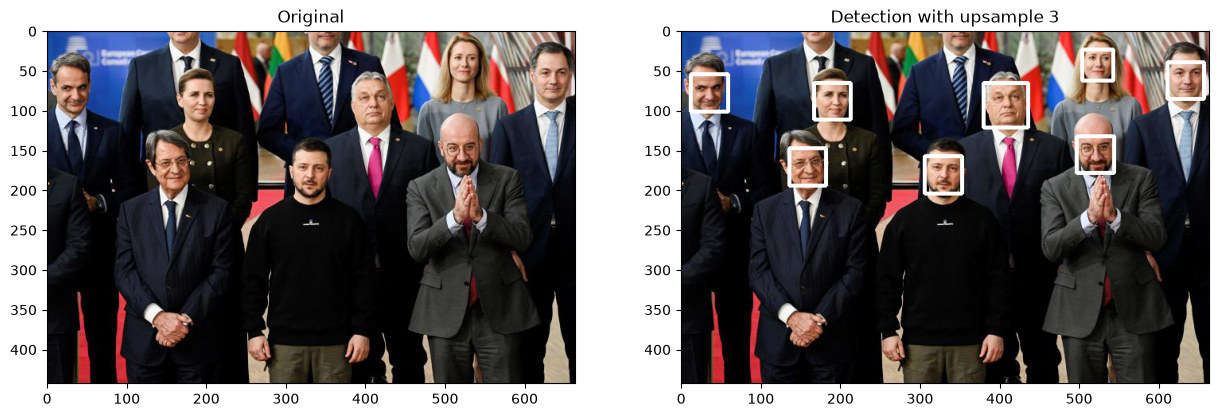

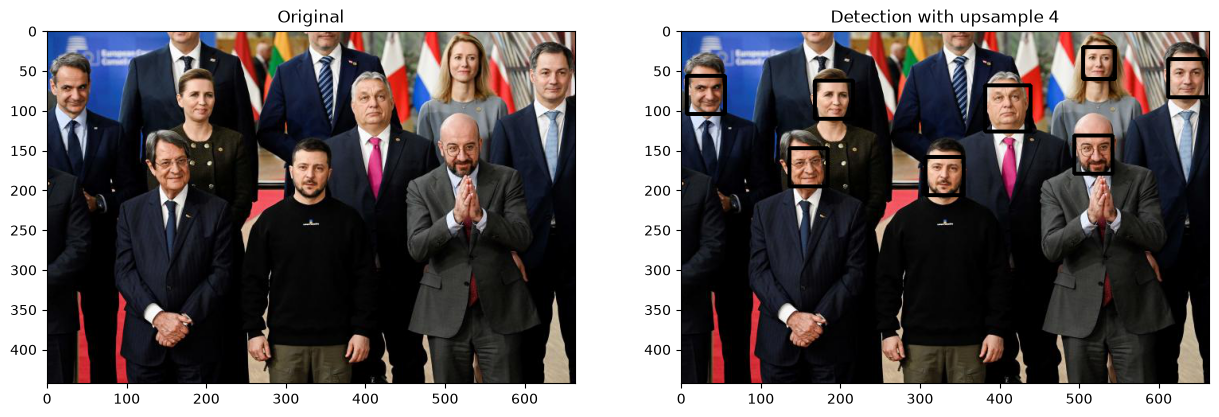

In [105]:
# lets take the original image and make its copy, draw detection and return it
def draw_detection_rectangles_on_image(img, rects, color):
    img_result = img.copy()
    for rect in rects:
        left_top_corner = (rect.left(), rect.top())
        right_bottom_corner = (rect.right(), rect.bottom())
        cv2.rectangle(img_result, left_top_corner, right_bottom_corner, color, 3)
    return img_result

# now it is time to make some test with upscale parameters
# if internet does not lie upscale means 0 - original image size, 1 - it is scalled x2, 2 scaled x4
# the numbers 3, 4 could be overkill for this image, but lets see
# also lets define colors, just pretent for now that number of colors and upscales is equal not to get out of bounds exception
upsmaples = [0, 1, 2, 3, 4]
colors = [COLOR_RED, COLOR_GREEN, COLOR_BLUE, COLOR_WHITE, COLOR_BLACK]

def run_detection_test(img, img_gray, upsmaples, colors):
    for i in range(len(upscales)):
        detections = dlib_face_detector(img_gray, dlbib_face_detector, upsmaples[i])
        img_with_detections = draw_detection_rectangles_on_image(img, detections, colors[i])
        display_image([img, img_with_detections], ["Original", "Detection with upsample %d" % upsmaples[i]])
    return

run_detection_test(img, img_gray, upsmaples, colors)
    

### Some notes

This is an image with no large amount of faces in it, but we can see performing no upsmapling at all, meaning leaving the parameter as 0 gives us 3 detections instead of 8 as any other result, as well the result without upsampling gives us a bigger detection rectangles so the detection is not so precise. In our case any value bigger that 1 are overkill and just gives us the same results but with different execution speed.

Now lets have so me fun with a biggest selfie in the world :)


### Step 5 (optional)

Repeat the process with a different and more challenging image (more faces, smaller faces, people with glasses, hats, helmets, etc.). How does the detector perform? Is it robust?

A: So as a testing image I have chosen the largest selfie in the world that has faces of different scales and people wearing hats, glasses etc, basically a very complex inage. So taking into account how many faces are in the image and some rough analysis of the results I can say that this detector does its job pretty well, by changing the upsample parameter gives better results, especially from 1 to 2 has a significant jump in number of detections.

Number of faces detected: 14
Number of faces detected: 83
Number of faces detected: 155
Number of faces detected: 165
Number of faces detected: 177


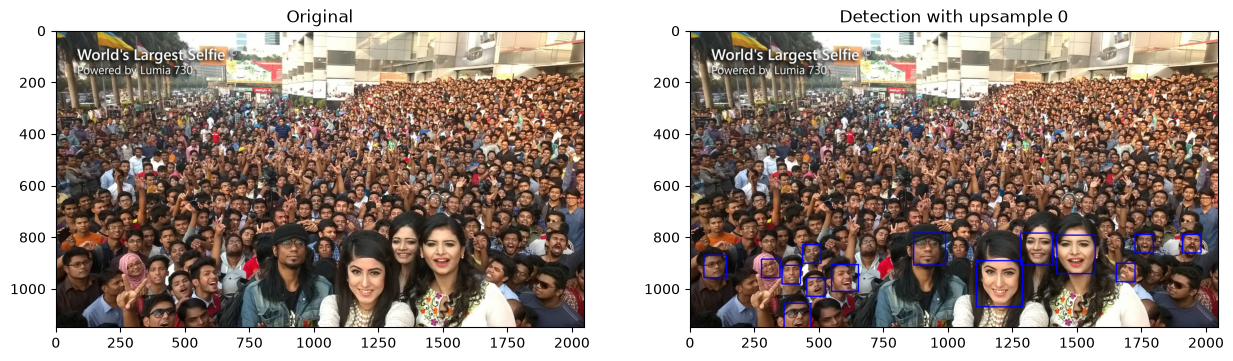

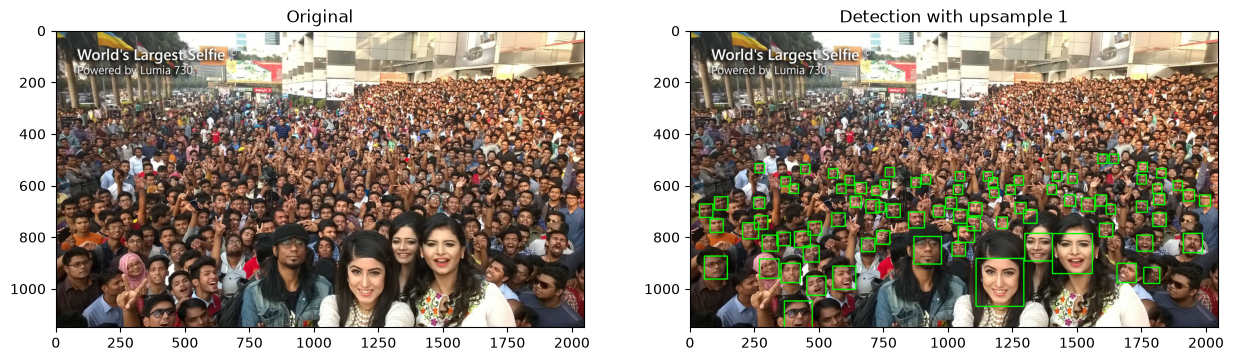

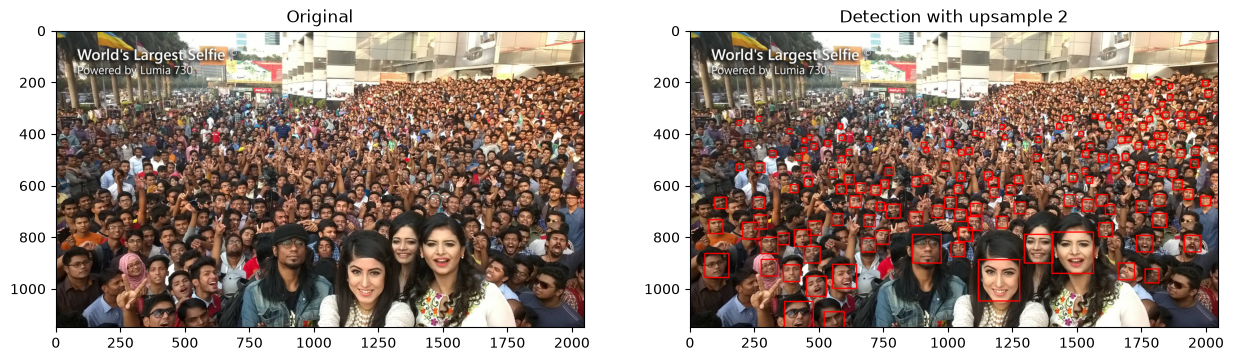

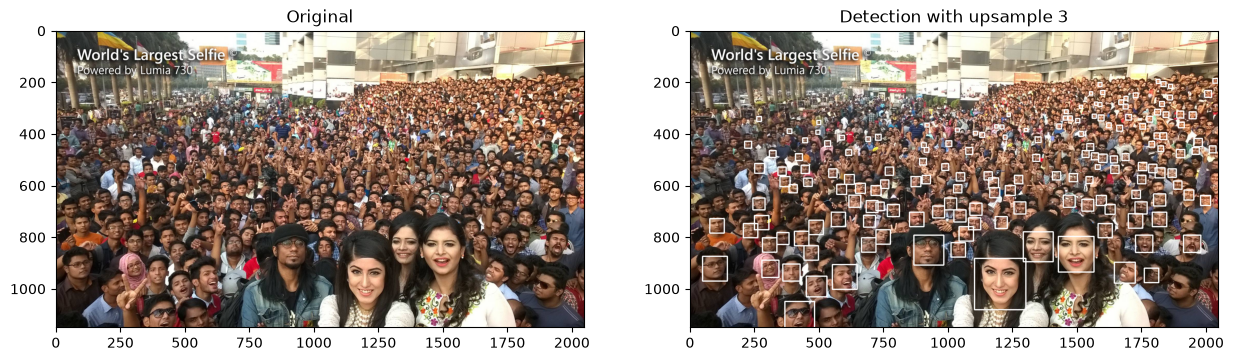

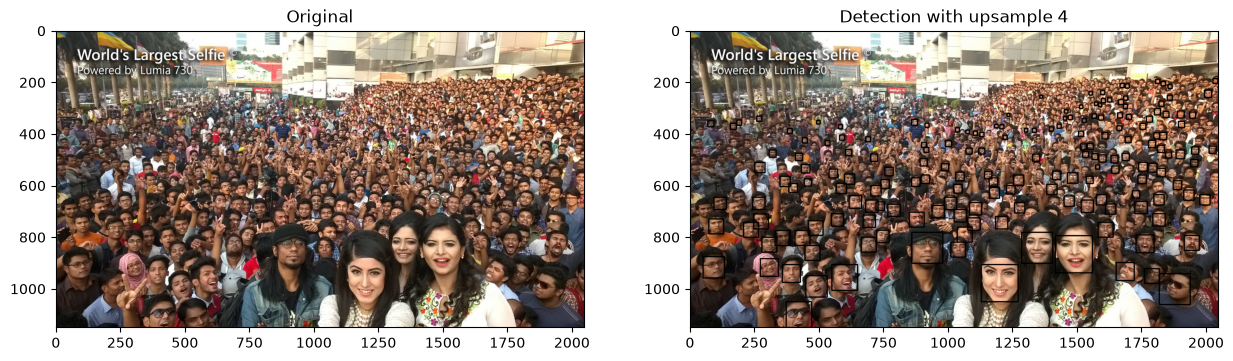

In [107]:
# now lets load biggest selfie in the world :)
img = dlib.load_rgb_image(selfie_img_path)
img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

run_detection_test(img, img_gray, upsmaples, colors)